<a href="https://colab.research.google.com/github/pratikshashinde4537/ml3/blob/main/ML3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

iris = sns.load_dataset("iris")
df = pd.DataFrame(iris)
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
df.tail()

,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [ ]:
df.median(numeric_only=True)

,0
sepal_length,5.80
sepal_width,3.00
petal_length,4.35
petal_width,1.30


In [ ]:
df.min(numeric_only=True)

,0
sepal_length,4.3
sepal_width,2.0
petal_length,1.0
petal_width,0.1


In [ ]:
df.std(numeric_only=True)

,0
sepal_length,0.828066
sepal_width,0.435866
petal_length,1.765298
petal_width,0.762238


In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["species"]=le.fit_transform(df["species"])
print(df.head())
print(df.tail())



   sepal_length  sepal_width  petal_length  petal_width  species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0
     sepal_length  sepal_width  petal_length  petal_width  species
145           6.7          3.0           5.2          2.3        2
146           6.3          2.5           5.0          1.9        2
147           6.5          3.0           5.2          2.0        2
148           6.2          3.4           5.4          2.3        2
149           5.9          3.0           5.1          1.8        2


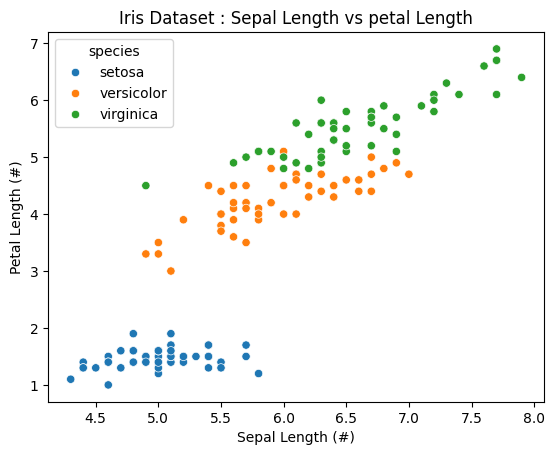

In [ ]:
sns.scatterplot(
    data=iris,
    x="sepal_length",
    y="petal_length",
    hue="species",

)

#add title and labels
plt.title("Iris Dataset : Sepal Length vs petal Length")
plt.xlabel("Sepal Length (#)")
plt.ylabel("Petal Length (#)")

plt.show()

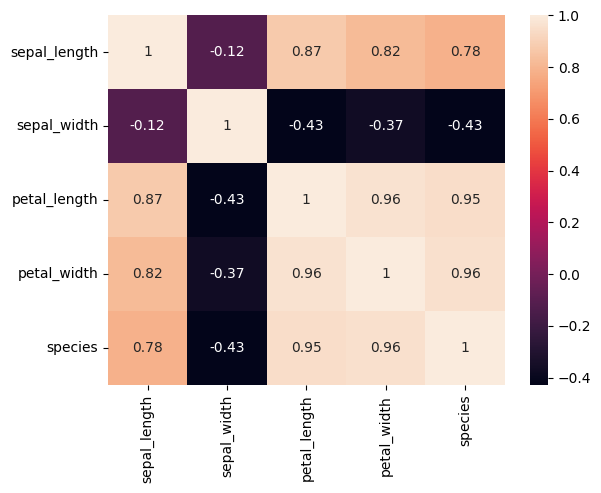

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Correlation = df.corr(numeric_only=True)
sns.heatmap(Correlation, annot=True)

plt.show()

In [ ]:
# from re import X # Remove or comment out this incorrect import
from sklearn.model_selection import train_test_split

# Define X and y from the DataFrame
X = df.drop('species', axis=1) # Features
y = df['species'] # Target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
    )
print("X_train shape:",X_train.shape) # Use .shape attribute
print("X_test shape:",X_test.shape)
print("y_train shape:",y_train.shape)
print("y_test shape:",y_test.shape)

# These lines are comments about expected shapes and should be commented out
# X_train; (120,4)
# X_test; (30,4)
# y_train; (120,)
# y_test; (30,)

from sklearn.neighbors import KNeighborsClassifier

model= KNeighborsClassifier(n_neighbors=5)
model.fit(X_train,y_train)

y_pred=model.predict(X_test)

print("Predicted Values:")
print(y_pred)

# This line is expected output and should be commented out
# Predicted Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

new_data=[[5.1, 3.5, 1.4, 0.2]]
prediction=model.predict(new_data) # Corrected typo: mpdel to model
print("Predicted Class:",prediction)

# This line is expected output and should be commented out
# Predicted Class: [0]

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)
Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Class: [0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100,"%")

# Accuracy: 100.0 %  # This line caused the error and has been commented out

Accuracy: 100.0 %


In [ ]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)

print("confusion Matrix:")
print(cm)


confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [ ]:
from sklearn.metrics import classification_report
print("Classification Report:")

print(classification_report(y_test,y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

